# ECSE 551 Assignment 1 — Task 1: data exploration

This notebook combines the former `task1.py`, `task1_analysis.py`, and
`task1_feature_plots.py`. It loads the Diabetes and Digits datasets, checks
missing feature values, exports CSV files, calculates statistics, and creates
overview and individual-feature plots.

Run the cells **from top to bottom** while the working directory is the folder
containing this notebook. The `target` column is the value to predict and is
never included among the input features. The notebook generates 222 individual
plots plus seven overview plots in `task1_results/`.

## 1. Import libraries and set output paths

`pandas` stores tabular data, NumPy supports numerical work, Matplotlib draws
figures, and `load_diabetes`/`load_digits` provide the datasets. `ROOT` is the
current folder; all CSV files and results are saved relative to it so the
notebook does not depend on a personal absolute path.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes, load_digits

ROOT = Path.cwd()
RESULTS = ROOT / "task1_results"
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print("Working folder:", ROOT)

Working folder: /Users/pmiroir/Documents/交作业用/ECSE_551_A1

## 2. Load Diabetes

There are 442 patients and 10 input features. `load_diabetes()` returns
already centered and scaled features, so values such as BMI can be negative
without representing a negative physical BMI. The separate `target` contains
the numerical disease-progression outcome one year later.

In [2]:
diabetes_bundle = load_diabetes()
diabetes_features = list(diabetes_bundle.feature_names)
df_diabetes = pd.DataFrame(diabetes_bundle.data, columns=diabetes_features)
df_diabetes["target"] = diabetes_bundle.target
print("Diabetes shape:", df_diabetes.shape)
print("Features:", diabetes_features)
print(df_diabetes.head(3).to_string(index=False))

Diabetes shape: (442, 11)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
      age       sex       bmi        bp        s1        s2        s3        s4        s5        s6  target
 0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401 -0.002592  0.019907 -0.017646   151.0
-0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412 -0.039493 -0.068332 -0.092204    75.0
 0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356 -0.002592  0.002861 -0.025930   141.0

## 3. Load Digits

Each row represents one 8×8 handwritten-digit image. The 64 columns
`pixel_0` through `pixel_63` store pixel intensities from 0 to 16; zero is a
valid blank pixel. The `target` column contains the correct digit from 0 to 9.

In [3]:
digits_bundle = load_digits()
digits_features = [f"pixel_{i}" for i in range(digits_bundle.data.shape[1])]
df_digits = pd.DataFrame(digits_bundle.data, columns=digits_features)
df_digits["target"] = digits_bundle.target
print("Digits shape:", df_digits.shape)
print("First image label:", df_digits.loc[0, "target"])
print("First image's first eight pixels:", df_digits.loc[0, digits_features[:8]].tolist())

Digits shape: (1797, 65)
First image label: 0
First image's first eight pixels: [0.0, 0.0, 5.0, 13.0, 9.0, 1.0, 0.0, 0.0]

## 4. Check missing feature values and remove incomplete rows

`isna().any(axis=1)` marks a row when **at least one input feature** is
missing. `dropna(subset=features)` then removes only those rows. The feature
matrix `X` and target array `y` are rebuilt from the cleaned DataFrames so
their rows stay aligned. We do not treat valid zero pixels as missing values.

In [4]:
def remove_incomplete_rows(data, features, name):
    missing_rows = data[features].isna().any(axis=1)
    print(f"{name}: {missing_rows.sum()} of {len(data)} rows have a missing feature")
    cleaned = data.dropna(subset=features).copy()
    print(f"{name}: {len(cleaned)} rows remain")
    return cleaned


df_diabetes = remove_incomplete_rows(df_diabetes, diabetes_features, "Diabetes")
df_digits = remove_incomplete_rows(df_digits, digits_features, "Digits")
X_diabetes = df_diabetes[diabetes_features].to_numpy()
y_diabetes = df_diabetes["target"].to_numpy()
X_digits = df_digits[digits_features].to_numpy()
y_digits = df_digits["target"].to_numpy()

Diabetes: 0 of 442 rows have a missing feature
Diabetes: 442 rows remain
Digits: 0 of 1797 rows have a missing feature
Digits: 1797 rows remain

## 5. Save the cleaned datasets

The two model-ready CSV files contain all input features and a final `target`
column. `index=False` avoids adding an artificial row-number feature.
`diabetes_raw.csv` is kept only to inspect unscaled physical values; model
analysis below uses the scaled Diabetes data specified by the assignment.

In [5]:
df_diabetes.to_csv(ROOT / "diabetes.csv", index=False)
df_digits.to_csv(ROOT / "digits.csv", index=False)
diabetes_raw = load_diabetes(scaled=False)
df_diabetes_raw = pd.DataFrame(
    diabetes_raw.data, columns=diabetes_raw.feature_names
)
df_diabetes_raw.to_csv(ROOT / "diabetes_raw.csv", index=False)
print("Saved diabetes.csv, digits.csv, and diabetes_raw.csv")

Saved diabetes.csv, digits.csv, and diabetes_raw.csv

## 6. Read the exported CSV files

Reading them back verifies that the analysis uses the saved files. The
following cells use `diabetes_data` and `digits_data` so the original dataset
objects remain available if needed.

In [6]:
diabetes_data = pd.read_csv(ROOT / "diabetes.csv")
digits_data = pd.read_csv(ROOT / "digits.csv")
assert diabetes_data.shape == df_diabetes.shape
assert digits_data.shape == df_digits.shape
print("Diabetes CSV:", diabetes_data.shape)
print("Digits CSV:", digits_data.shape)

Diabetes CSV: (442, 11)
Digits CSV: (1797, 65)

## 7. Mean, minimum, and maximum for every input feature

The function calculates these three statistics for **all 10 Diabetes
features and all 64 Digits features**. It saves one CSV table per dataset in
the corresponding `stats/` folder. The Diabetes target is continuous, so its
mean and range are meaningful; Digits labels are categories, so we show class
counts instead of averaging the labels.

In [7]:
def save_feature_stats(data, features, name):
    stats = (
        data[features]
        .agg(["mean", "min", "max"])
        .T.rename_axis("feature")
        .reset_index()
    )
    folder = RESULTS / name / "stats"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / f"{name}_feature_stats.csv"
    stats.to_csv(path, index=False)
    print(f"{name}: saved {len(stats)} feature rows to {path}")
    return stats


diabetes_stats = save_feature_stats(diabetes_data, diabetes_features, "diabetes")
digits_stats = save_feature_stats(digits_data, digits_features, "digits")
print()
print("Diabetes features:")
print(diabetes_stats.to_string(index=False))
print()
print("Digits features:")
print(digits_stats.to_string(index=False))
print()
print("Diabetes target mean/min/max:",
      diabetes_data["target"].agg(["mean", "min", "max"]).to_dict())
print("Digits class counts:",
      digits_data["target"].value_counts().sort_index().to_dict())

diabetes: saved 10 feature rows to /Users/pmiroir/Documents/交作业用/ECSE_551_A1/task1_results/diabetes/stats/diabetes_feature_stats.csv
digits: saved 64 feature rows to /Users/pmiroir/Documents/交作业用/ECSE_551_A1/task1_results/digits/stats/digits_feature_stats.csv

Diabetes features:
feature          mean       min      max
    age -7.284269e-18 -0.107226 0.110727
    sex  2.348549e-17 -0.044642 0.050680
    bmi -2.087320e-16 -0.090275 0.170555
     bp -4.571507e-17 -0.112399 0.132044
     s1 -9.293722e-18 -0.126781 0.153914
     s2  4.420798e-17 -0.115613 0.198788
     s3  2.135044e-18 -0.102307 0.181179
     s4  2.913707e-17 -0.076395 0.185234
     s5  9.143013e-17 -0.126097 0.133597
     s6  1.431736e-17 -0.137767 0.135612

Digits features:
 feature      mean  min  max
 pixel_0  0.000000  0.0  0.0
 pixel_1  0.303840  0.0  8.0
 pixel_2  5.204786  0.0 16.0
 pixel_3 11.835838  0.0 16.0
 pixel_4 11.848080  0.0 16.0
 pixel_5  5.781859  0.0 16.0
 pixel_6  1.362270  0.0 16.0
 pixel_7  0.129661 

## 8. Inspect correlations and constant pixels

Pearson correlation measures linear association between two features. The
function ignores a feature's correlation with itself and skips constant
columns, whose correlation is undefined. A strong correlation is descriptive;
it does not prove one feature causes another. Constant zero pixels contain no
variation in this dataset.

In [8]:
def strongest_correlation(data, features):
    correlation = data[features].corr().abs()
    values = correlation.to_numpy().copy()
    upper = np.triu(np.ones(values.shape, dtype=bool), k=1)
    values[~upper] = np.nan
    row, col = np.unravel_index(np.nanargmax(values), values.shape)
    first, second = features[row], features[col]
    return first, second, data[first].corr(data[second])


constant_pixels = digits_stats.loc[
    digits_stats["min"] == digits_stats["max"], "feature"
].tolist()
print("Constant Digits pixels:", constant_pixels)
for name, data, features in (
    ("Diabetes", diabetes_data, diabetes_features),
    ("Digits", digits_data, digits_features),
):
    first, second, r = strongest_correlation(data, features)
    print(f"{name}: strongest feature pair is {first} / {second}, r={r:.3f}")

Constant Digits pixels: ['pixel_0', 'pixel_32', 'pixel_39']
Diabetes: strongest feature pair is s1 / s2, r=0.897
Digits: strongest feature pair is pixel_2 / pixel_58, r=0.938

## 9. Overview: Diabetes boxplot

All 10 features are shown together because they are already on comparable
scaled ranges. The line inside each box is the median, the box covers the
middle half of observations, and individual circles mark potential outliers.
An outlier marker alone does not prove a recording error.

<cell 9>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

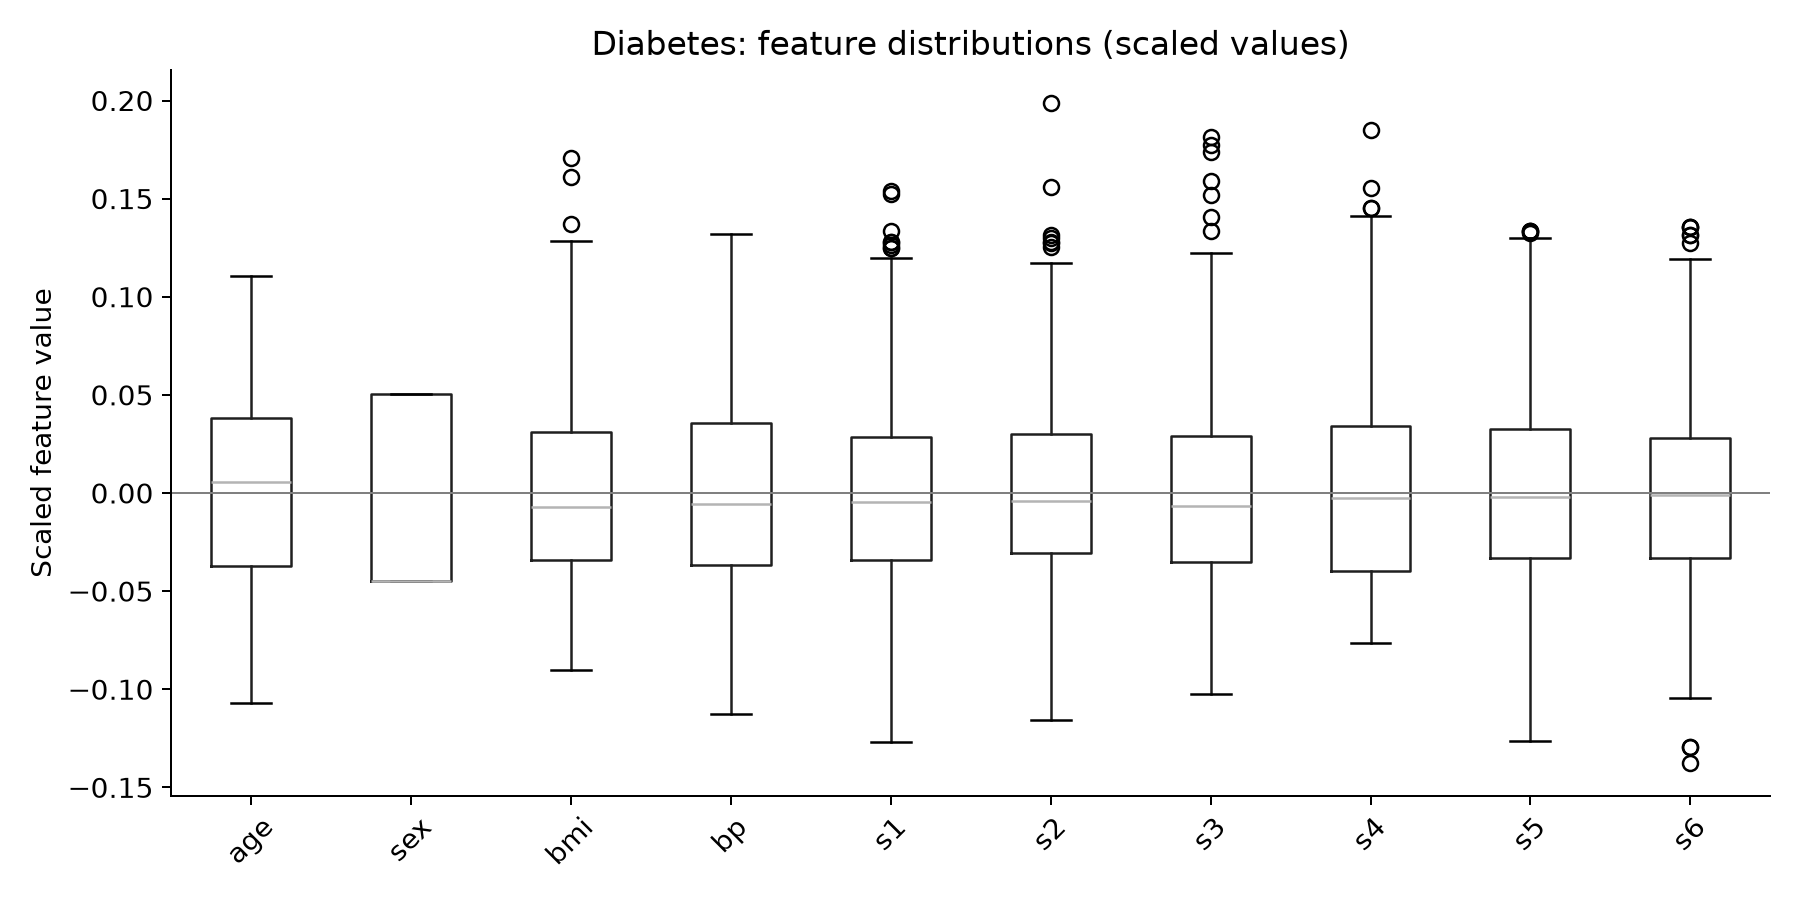

In [9]:
diabetes_overview = RESULTS / "diabetes" / "overview"
diabetes_overview.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(10, 5))
diabetes_data[diabetes_features].boxplot(ax=ax, rot=45, grid=False)
ax.set(title="Diabetes: feature distributions (scaled values)",
       ylabel="Scaled feature value")
ax.axhline(0, color="gray", linewidth=0.8)
fig.tight_layout()
fig.savefig(diabetes_overview / "diabetes_boxplot.png", dpi=180)
plt.show()
plt.close(fig)

## 10. Overview: Diabetes histograms

Histograms show how often values occur. The selected panels include `sex`,
whose two peaks reflect its two encoded categories, several continuous
features, and the continuous prediction target. These panels give a compact
overview; later cells save a separate histogram for every feature.

<cell 10>:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

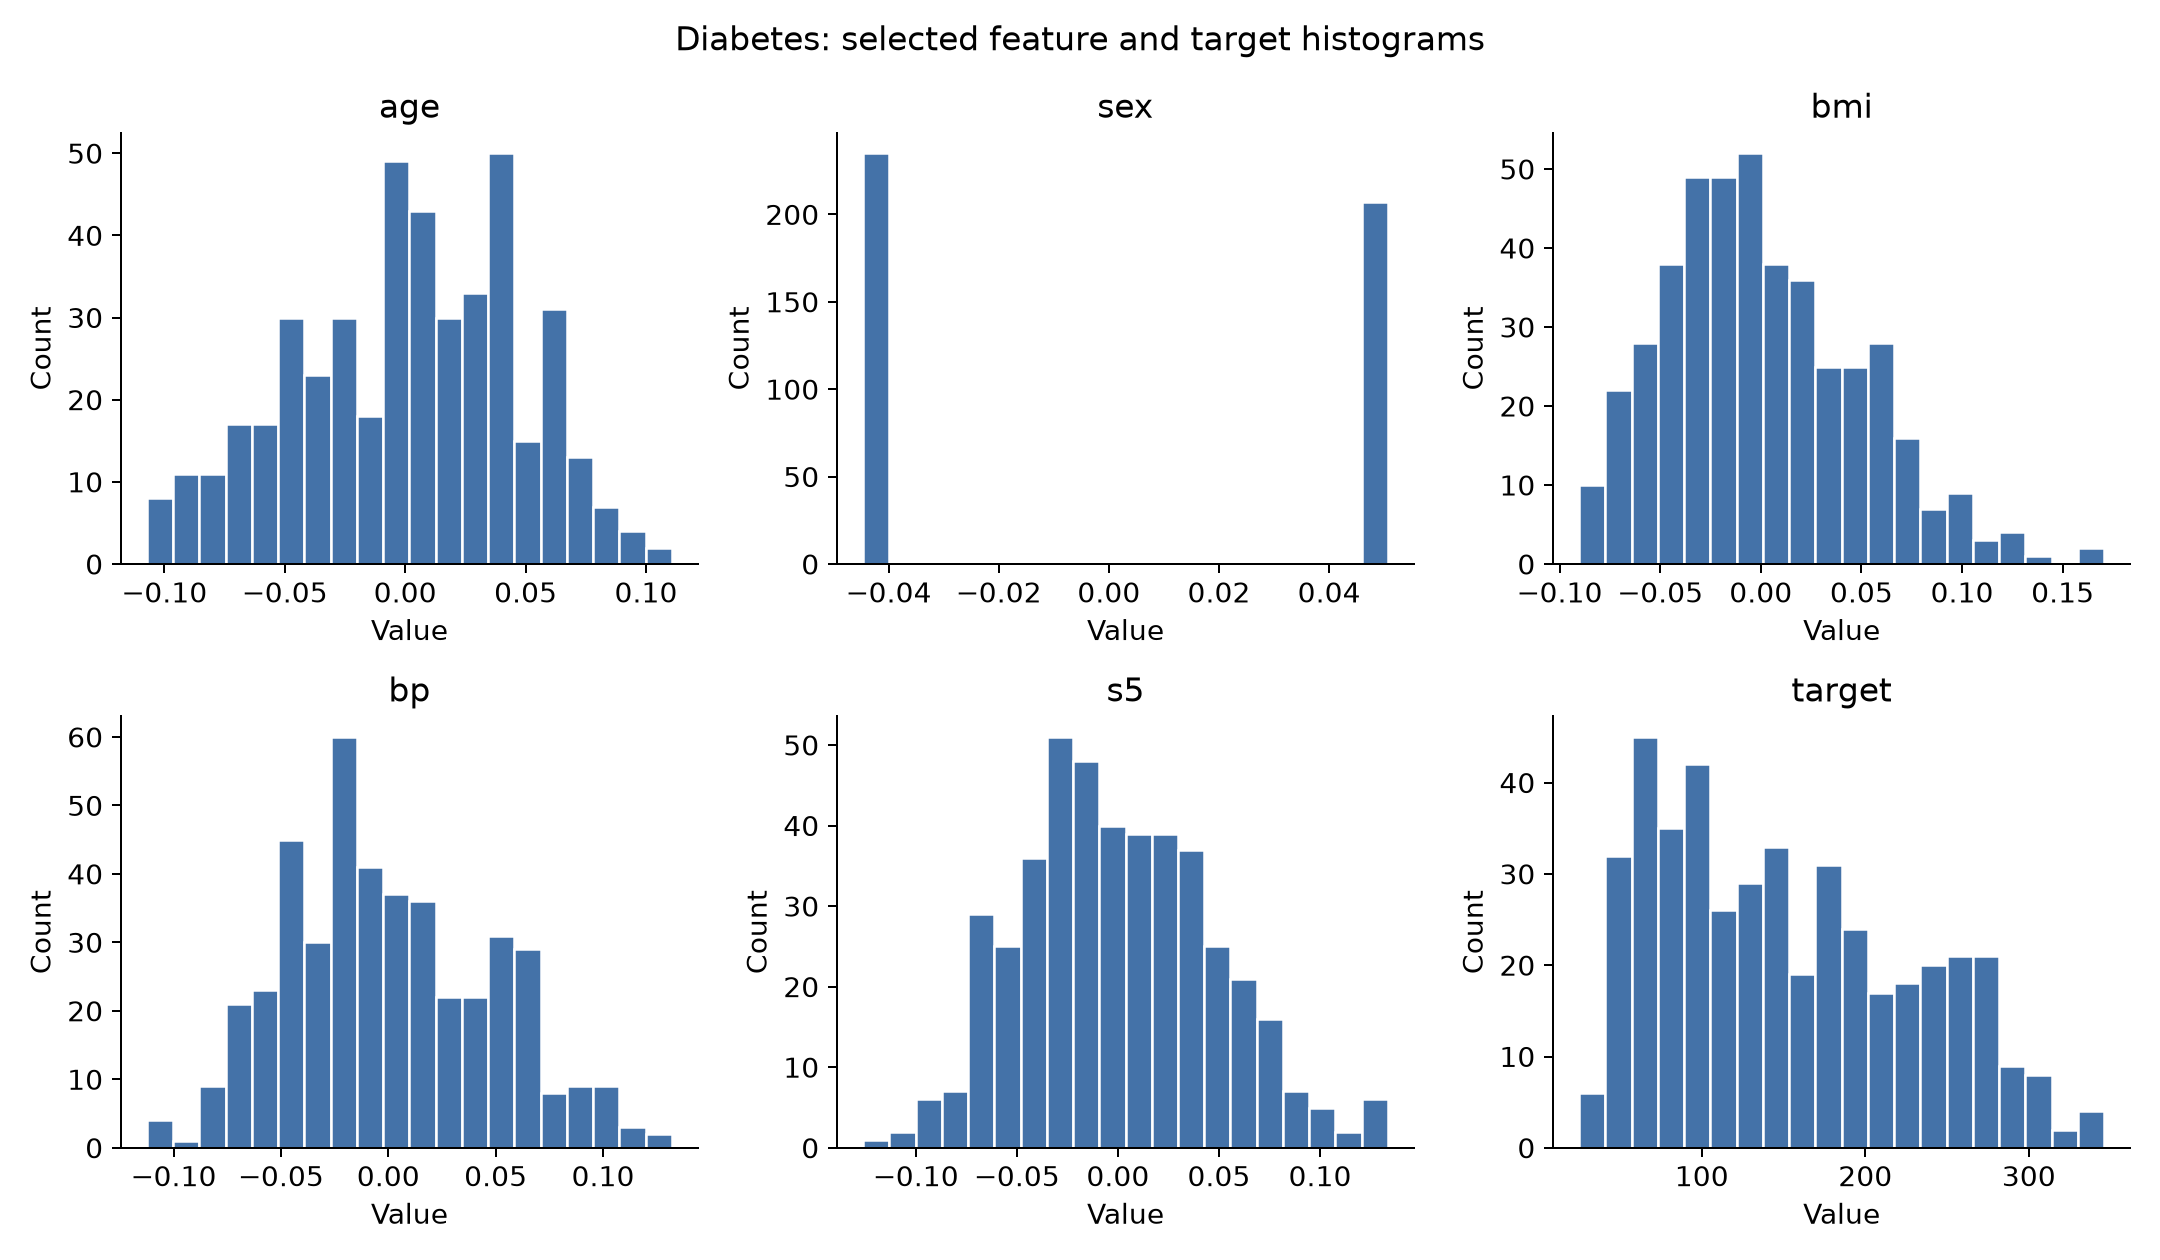

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, column in zip(axes.flat, ["age", "sex", "bmi", "bp", "s5", "target"]):
    ax.hist(diabetes_data[column], bins=20, color="#4472a8", edgecolor="white")
    ax.set(title=column, xlabel="Value", ylabel="Count")
fig.suptitle("Diabetes: selected feature and target histograms")
fig.tight_layout()
fig.savefig(diabetes_overview / "diabetes_histograms.png", dpi=180)
plt.show()
plt.close(fig)

## 11. Overview: Diabetes scatterplots

The left plot compares BMI with the outcome; an upward pattern suggests a
positive association. The right plot compares two serum measurements (`s1`
and `s2`) to visualize their correlation. Neither plot establishes causality.
Every Diabetes feature also receives its own feature-versus-target scatterplot
later in the notebook.

<cell 11>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

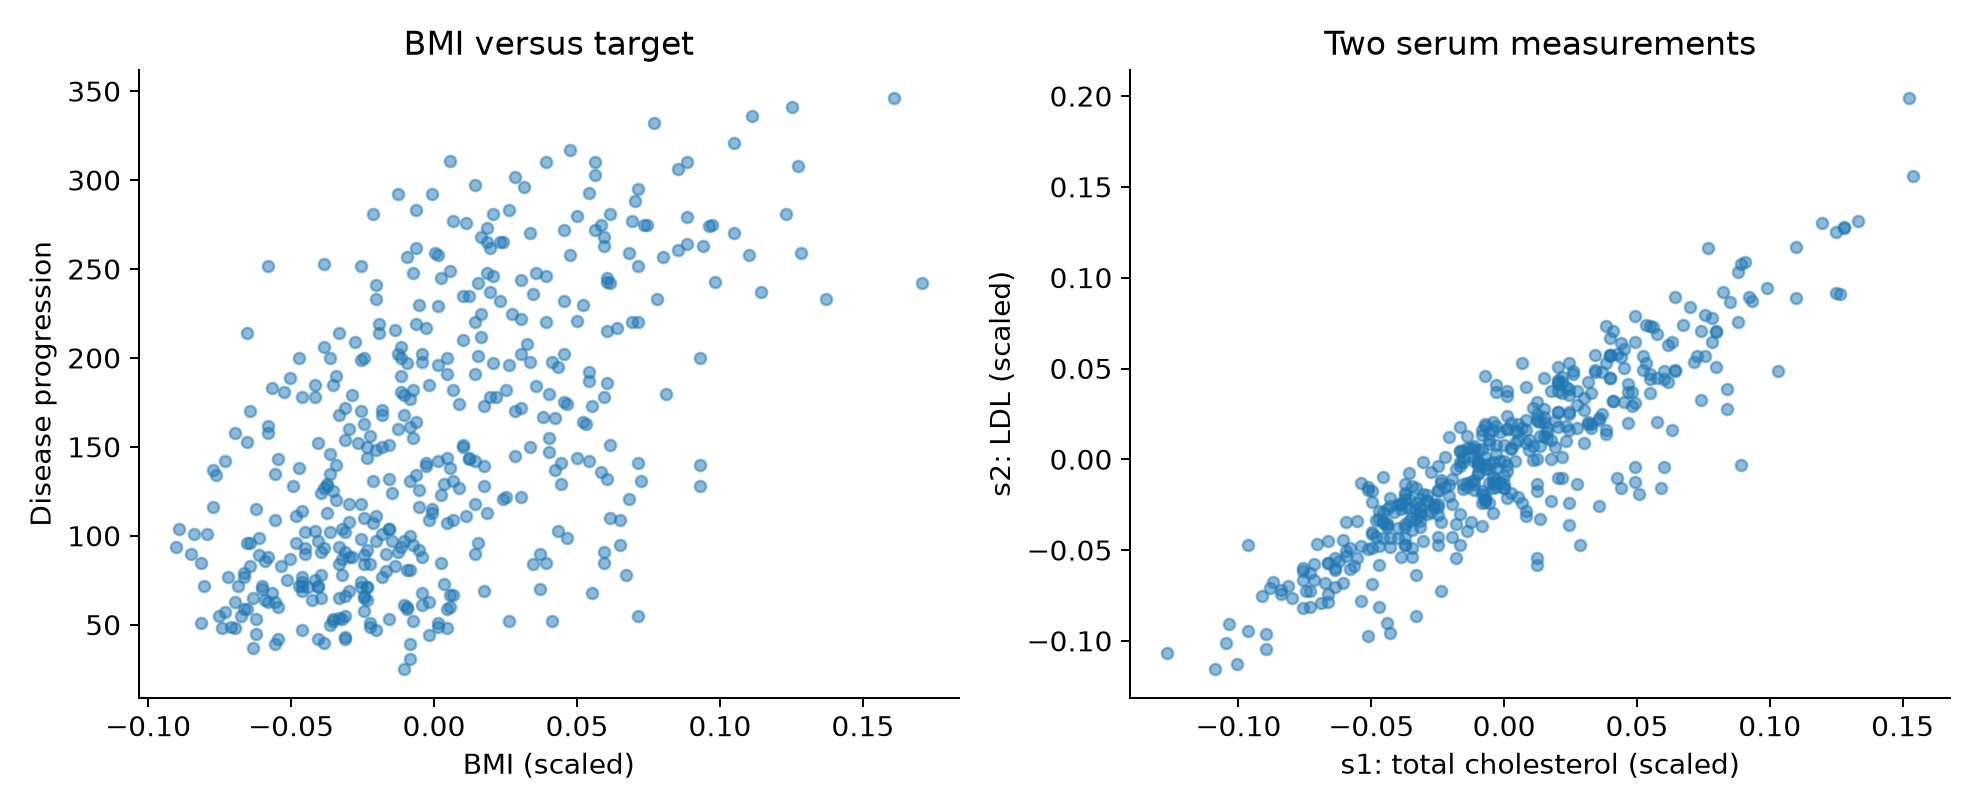

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(diabetes_data["bmi"], diabetes_data["target"],
                alpha=0.5, s=20)
axes[0].set(xlabel="BMI (scaled)", ylabel="Disease progression",
            title="BMI versus target")
axes[1].scatter(diabetes_data["s1"], diabetes_data["s2"],
                alpha=0.5, s=20)
axes[1].set(xlabel="s1: total cholesterol (scaled)",
            ylabel="s2: LDL (scaled)", title="Two serum measurements")
fig.tight_layout()
fig.savefig(diabetes_overview / "diabetes_scatterplots.png", dpi=180)
plt.show()
plt.close(fig)

## 12. Overview: Digits boxplot

Plotting all 64 pixel boxes in one figure would be difficult to read. This
overview chooses the six pixels with the largest variance, while later cells
save a boxplot for **every** pixel. A pixel at intensity zero is blank, not
missing.

Selected pixels: ['pixel_42', 'pixel_43', 'pixel_34', 'pixel_35', 'pixel_44', 'pixel_21']

<cell 12>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

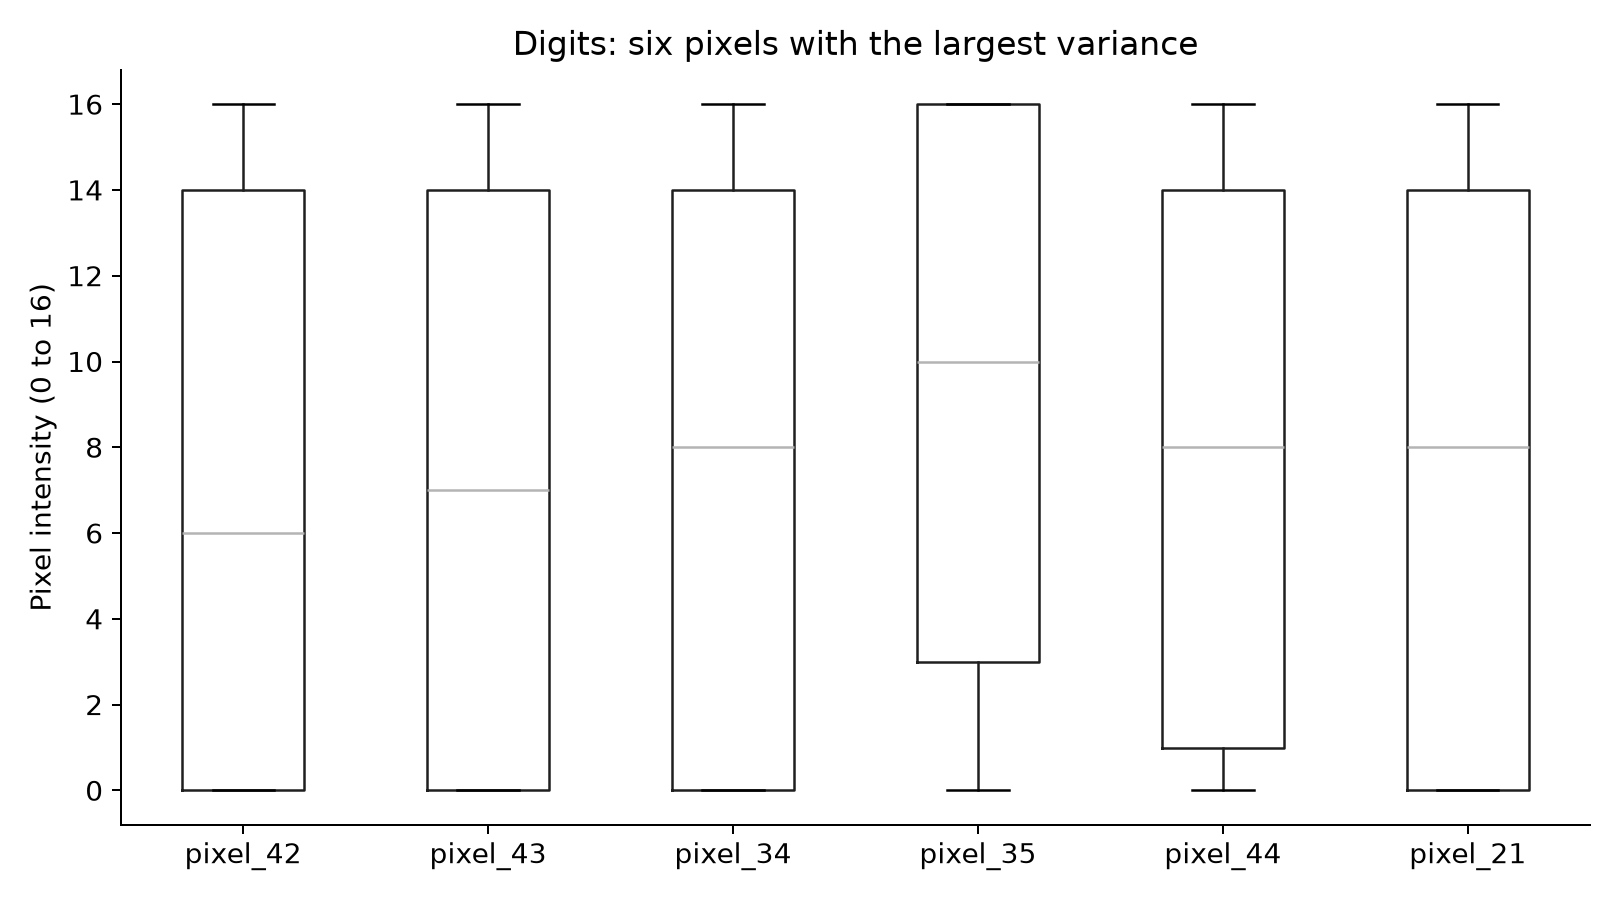

In [12]:
digits_overview = RESULTS / "digits" / "overview"
digits_overview.mkdir(parents=True, exist_ok=True)
selected_pixels = digits_data[digits_features].var().nlargest(6).index.tolist()
print("Selected pixels:", selected_pixels)
fig, ax = plt.subplots(figsize=(9, 5))
digits_data[selected_pixels].boxplot(ax=ax, grid=False)
ax.set(title="Digits: six pixels with the largest variance",
       ylabel="Pixel intensity (0 to 16)")
fig.tight_layout()
fig.savefig(digits_overview / "digits_boxplot.png", dpi=180)
plt.show()
plt.close(fig)

## 13. Overview: Digits histograms

The bars are centered on the integer pixel intensities 0 through 16. A high
bar at zero means the location is blank in many images. Peaks near 16 mean
the location often contains a dark stroke. Separate histograms for all 64
pixels are generated below.

<cell 13>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

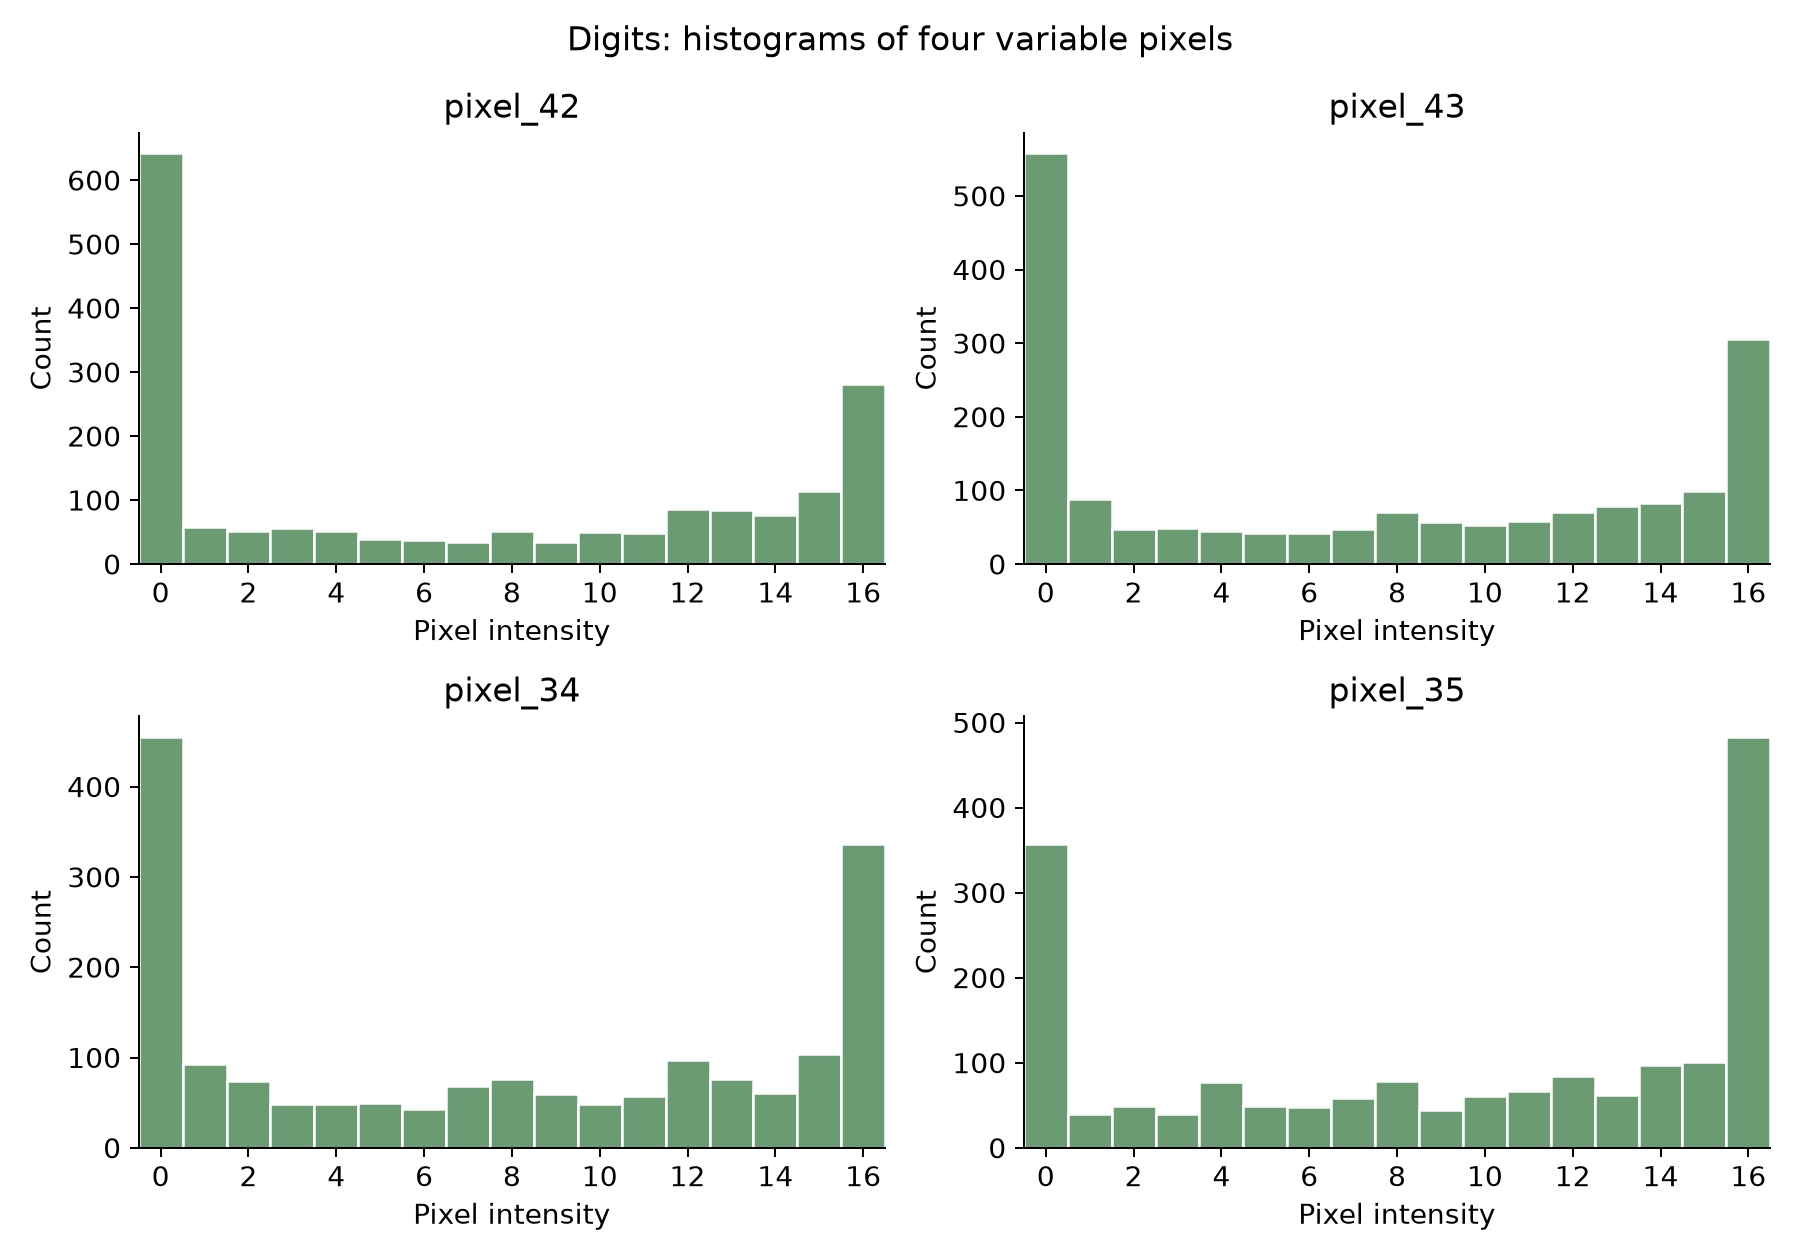

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, column in zip(axes.flat, selected_pixels[:4]):
    ax.hist(digits_data[column], bins=np.arange(-0.5, 17.5, 1),
            color="#6b9b73", edgecolor="white")
    ax.set(title=column, xlabel="Pixel intensity", ylabel="Count",
           xlim=(-0.5, 16.5))
fig.suptitle("Digits: histograms of four variable pixels")
fig.tight_layout()
fig.savefig(digits_overview / "digits_histograms.png", dpi=180)
plt.show()
plt.close(fig)

## 14. Overview: image density by digit class

For each image, `ink_count` counts nonzero pixels and
`average_intensity` averages all 64 pixel values. The scatterplot explores
whether the density of handwriting varies across digit classes. The color
shows the categorical answer, not a continuous numerical target.

<cell 14>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

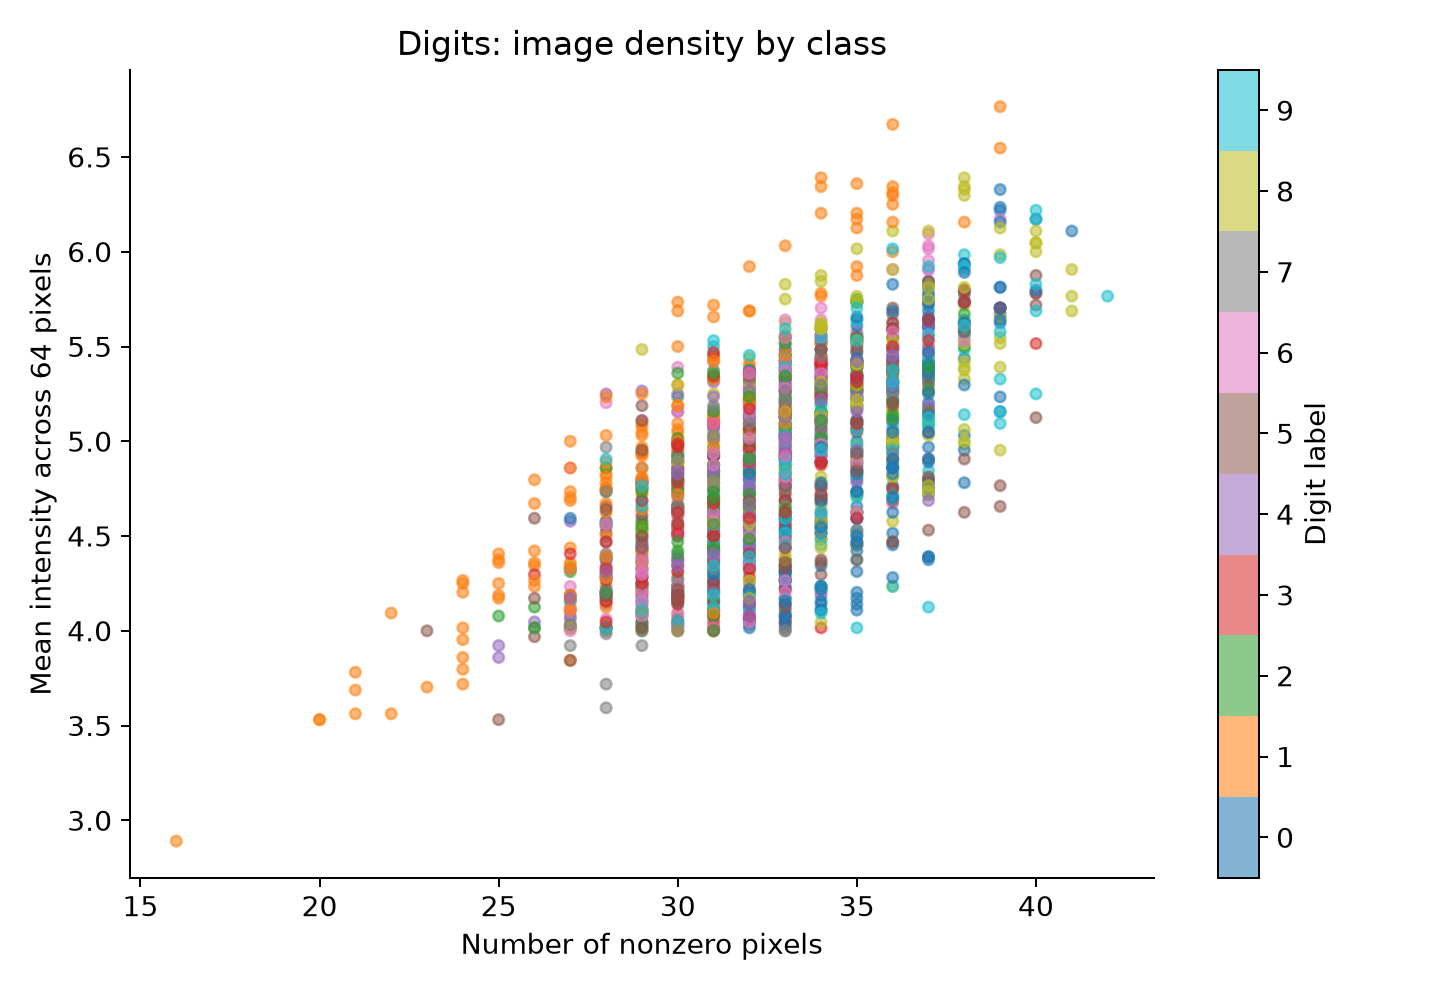

In [14]:
pixels = digits_data[digits_features].to_numpy()
ink_count = (pixels > 0).sum(axis=1)
average_intensity = pixels.mean(axis=1)
fig, ax = plt.subplots(figsize=(8, 5.5))
points = ax.scatter(ink_count, average_intensity,
                    c=digits_data["target"], cmap="tab10",
                    vmin=-0.5, vmax=9.5, alpha=0.55, s=18)
colorbar = fig.colorbar(points, ax=ax, ticks=range(10))
colorbar.set_label("Digit label")
ax.set(xlabel="Number of nonzero pixels",
       ylabel="Mean intensity across 64 pixels",
       title="Digits: image density by class")
fig.tight_layout()
fig.savefig(digits_overview / "digits_scatterplot.png", dpi=180)
plt.show()
plt.close(fig)

## 15. Overview: average 8×8 pixel image

Reshaping the 64 feature means back to 8×8 preserves their positions in the
image. Brighter cells have a larger average intensity; dark border cells are
usually blank. This summarizes all 64 pixel means spatially.

<cell 15>:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

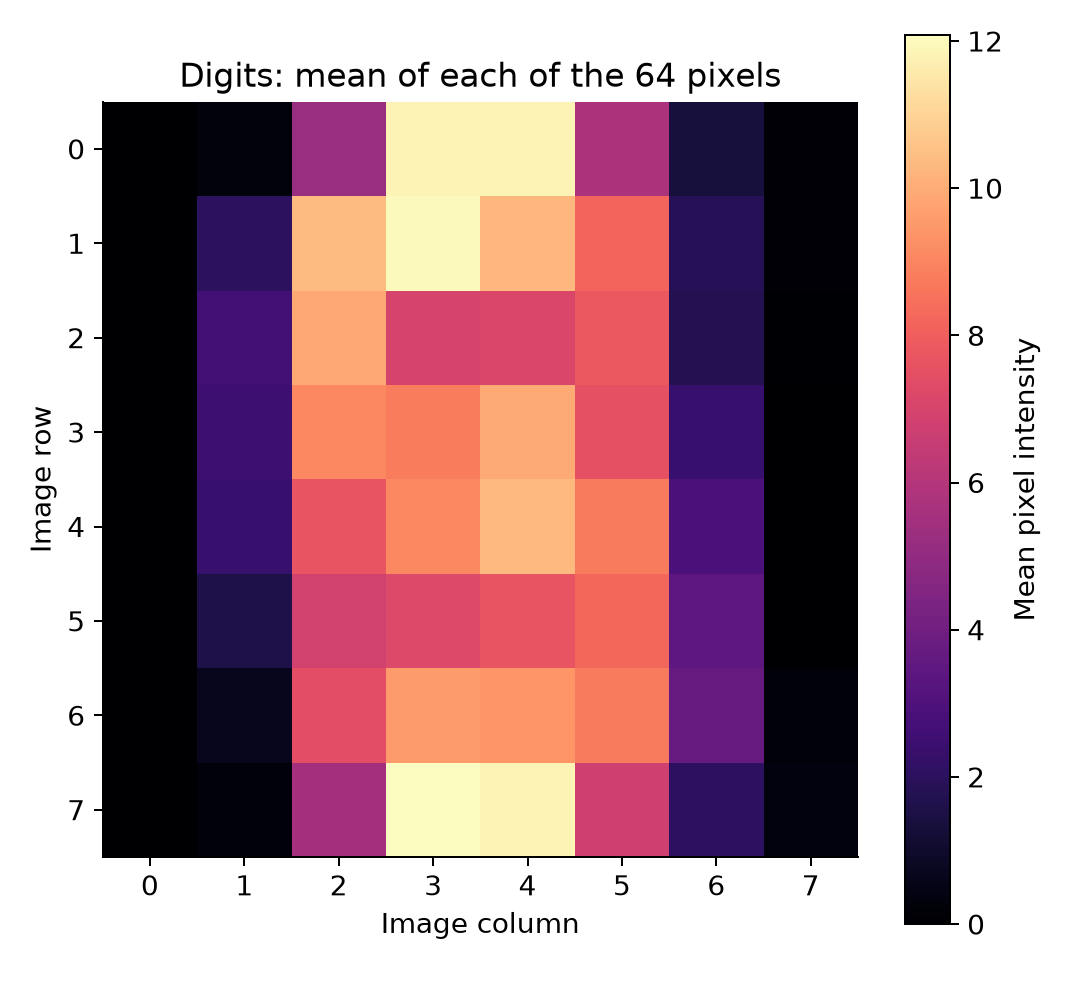

In [15]:
fig, ax = plt.subplots(figsize=(6, 5.5))
heatmap = ax.imshow(pixels.mean(axis=0).reshape(8, 8), cmap="magma")
fig.colorbar(heatmap, ax=ax, label="Mean pixel intensity")
ax.set(title="Digits: mean of each of the 64 pixels",
       xlabel="Image column", ylabel="Image row")
fig.tight_layout()
fig.savefig(digits_overview / "digits_mean_pixel_heatmap.png", dpi=180)
plt.show()
plt.close(fig)

## 16. Helper for individual Diabetes plots

For **each** of the 10 Diabetes input features, this function saves a
boxplot, a histogram, and a scatterplot against the continuous target. The
feature is the input; the target is shown only for comparison. Each plot is
placed in its dataset and chart-type folder.

In [16]:
def save_detail_plot(fig, path):
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)


def plot_diabetes_feature(data, feature, folders):
    values = data[feature]

    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.boxplot(values, tick_labels=[feature], showmeans=True)
    ax.set(title=f"Diabetes: {feature} boxplot",
           ylabel="Scaled feature value")
    save_detail_plot(fig, folders["boxplots"] / f"{feature}.png")

    fig, ax = plt.subplots(figsize=(6, 4.5))
    bins = 2 if feature == "sex" else 25
    ax.hist(values, bins=bins, color="#4472a8", edgecolor="white")
    ax.set(title=f"Diabetes: {feature} histogram",
           xlabel="Scaled feature value", ylabel="Number of patients")
    save_detail_plot(fig, folders["histograms"] / f"{feature}.png")

    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.scatter(values, data["target"], s=20, alpha=0.55,
               color="#4472a8")
    ax.set(title=f"Diabetes: {feature} versus target",
           xlabel=f"{feature} (scaled)",
           ylabel="Disease progression after one year")
    save_detail_plot(fig, folders["scatterplots"] / f"{feature}.png")

## 17. Helper for individual Digits plots

The same three chart types are saved for **every** one of the 64 pixels. In
the scatterplot, the horizontal axis is the digit class and the vertical
axis is the pixel intensity. A small reproducible horizontal jitter separates
otherwise overlapping points; it does **not** alter the underlying data.
Even a constant-zero pixel is plotted, making its lack of variation visible.

In [17]:
def plot_digits_feature(data, feature, folders, class_jitter):
    values = data[feature]

    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.boxplot(values, tick_labels=[feature], showmeans=True)
    ax.set(title=f"Digits: {feature} boxplot",
           ylabel="Pixel intensity (0 to 16)", ylim=(-0.5, 16.5))
    save_detail_plot(fig, folders["boxplots"] / f"{feature}.png")

    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.hist(values, bins=np.arange(-0.5, 17.5, 1),
            color="#6b9b73", edgecolor="white")
    ax.set(title=f"Digits: {feature} histogram",
           xlabel="Pixel intensity", ylabel="Number of images",
           xlim=(-0.5, 16.5))
    save_detail_plot(fig, folders["histograms"] / f"{feature}.png")

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.scatter(data["target"] + class_jitter, values,
               s=8, alpha=0.18, color="#547caa")
    ax.set(title=f"Digits: {feature} by digit class",
           xlabel="Digit class (jittered for visibility)",
           ylabel="Pixel intensity", xticks=range(10),
           xlim=(-0.5, 9.5), ylim=(-0.5, 16.5))
    save_detail_plot(fig, folders["scatterplots"] / f"{feature}.png")

## 18. Generate all individual-feature figures

The loop creates `boxplots/`, `histograms/`, and `scatterplots/` under each
dataset folder. It saves **10 × 3 = 30 Diabetes plots** and **64 × 3 = 192
Digits plots**. Only the counts are printed here so the notebook stays
readable; open the image files to inspect a particular feature.

In [18]:
rng = np.random.default_rng(42)
for dataset_name, data, features in (
    ("diabetes", diabetes_data, diabetes_features),
    ("digits", digits_data, digits_features),
):
    folders = {
        chart_type: RESULTS / dataset_name / chart_type
        for chart_type in ("boxplots", "histograms", "scatterplots")
    }
    for folder in folders.values():
        folder.mkdir(parents=True, exist_ok=True)

    if dataset_name == "diabetes":
        for feature in features:
            plot_diabetes_feature(data, feature, folders)
    else:
        class_jitter = rng.uniform(-0.18, 0.18, size=len(data))
        for feature in features:
            plot_digits_feature(data, feature, folders, class_jitter)

    print(f"{dataset_name}: {len(features)} features × 3 chart types "
          f"= {len(features) * 3} individual plots")

diabetes: 10 features × 3 chart types = 30 individual plots
digits: 64 features × 3 chart types = 192 individual plots

## Interpretation and next step

- **Missing values:** neither dataset had a row with a missing input feature.
- **Diabetes scaling:** `load_diabetes()` already centers and scales the 10
  inputs. Their means are near zero and their ranges are comparable.
- **Digits scaling:** all pixels use the same 0–16 scale. Rescaling to 0–1 may
  help gradient-descent models in Task 2, although it is not needed to make
  one pixel's units comparable with another's.
- **Plots:** extreme values in a boxplot deserve inspection, but are not
  automatically errors. Zero-valued Digits pixels are valid blank pixels.

Task 2 should split data into training and test sets before fitting any new
scaling parameters. The categorical Digits target is not an input feature.